In [3]:
from pathlib import Path
rootDir = Path.cwd()

In [11]:
rootDir = "/content/drive/MyDrive/Paper3/HallucinationTaxonomy"

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from scipy.stats import spearmanr, wilcoxon
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

matplotlib.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.05,
})

CONDITIONS = ["Baseline", "T-Aware Generation", "T-Aware + CF Review"]
COND_FULL = {
    "Baseline": "Baseline",
    "T-Aware Generation": "Taxonomy-Aware Generation (A+C)",
    "T-Aware + CF Review": "T-Aware Generation + Code Faithfulness Review (A+B+C)",
}

COLORS = {
    'DeepSeek-R1-Qwen3-8B': '#2196F3',  # blue
    'Qwen3-32B': '#FF9800',              # orange
    'Qwen3-8B': '#4CAF50',               # green
}
CONDITION_COLORS = {
    'Baseline': '#9E9E9E',               # grey
    'T-Aware Generation': '#2196F3',     # blue
    'T-Aware + CF Review': '#FF9800',    # orange
}
MARKERS = {
    'DeepSeek-R1-Qwen3-8B': 'o',
    'Qwen3-32B': 's',
    'Qwen3-8B': '^',
}


print("=" * 60)
print("=" * 60)


DEEPSEEK_FILE = f"{rootDir}/Result/Mitigation/QwenDeepResult.xlsx"
QWEN32_FILE = f"{rootDir}/Result/Mitigation/Qwen32Result.xlsx"
QWEN8_FILE = f"{rootDir}/Result/Mitigation/Qwen8bResult.xlsx"
GOLD_FILE = f"{rootDir}/Result/Mitigation/GoldDataset2.csv"

COL_MAPS = {
    DEEPSEEK_FILE: {
        "Class Completeness": "ClassComp", "Attribute Completeness": "AttrComp",
        "Relationship Completeness": "RelComp", "Class Correctness": "ClassCorr",
        "Attribute Correctness": "AttrCorr", "Relationship Correctness": "RelCorr"
    },
    QWEN32_FILE: {
        "ClassCom": "ClassComp", "AttCom": "AttrComp", "RelCom": "RelComp",
        "ClassCorr": "ClassCorr", "AttCorr": "AttrCorr", "RelCorr": "RelCorr"
    },
    QWEN8_FILE: {
        "Class Comp.": "ClassComp", "Attr. Comp.": "AttrComp", "Rel. Comp.": "RelComp",
        "Class Corr.": "ClassCorr", "Attr. Corr.": "AttrCorr", "Rel. Corr.": "RelCorr"
    },
}

STANDARD_COLS = ["ClassComp", "AttrComp", "RelComp", "ClassCorr", "AttrCorr", "RelCorr"]
# Sheet order in Excel: 0=Baseline, 1=T-Aware Generation, 2=T-Aware + CF Review
SHEET_CONDS = ["Baseline", "T-Aware Generation", "T-Aware + CF Review"]

def read_model(path, col_map):
    results = {}
    for i, cond in enumerate(SHEET_CONDS):
        df = pd.read_excel(path, sheet_name=i)
        df = df.rename(columns=col_map)
        df = df[STANDARD_COLS]
        results[cond] = df
    return results

# Load everything
gold = pd.read_csv(GOLD_FILE)
gold['Complexity'] = gold['Classes'] + gold['Associations']

models = {
    'DeepSeek-R1-Qwen3-8B': read_model(DEEPSEEK_FILE, COL_MAPS[DEEPSEEK_FILE]),
    'Qwen3-32B': read_model(QWEN32_FILE, COL_MAPS[QWEN32_FILE]),
    'Qwen3-8B': read_model(QWEN8_FILE, COL_MAPS[QWEN8_FILE]),
}

model_names = list(models.keys())
print(f"\nLoaded {len(gold)} gold cases, {len(models)} models.")


Loaded 13 gold cases, 3 models.


In [ ]:
def f1(precision, recall):
    """Element-wise F1, handling zero denominators."""
    denom = precision + recall
    return np.where(denom > 0, 2 * precision * recall / denom, 0.0)

def compute_f1(df):
    """Compute per-dimension and overall F1 for a condition dataframe."""
    class_f1 = f1(df["ClassCorr"].values, df["ClassComp"].values)
    attr_f1 = f1(df["AttrCorr"].values, df["AttrComp"].values)
    rel_f1 = f1(df["RelCorr"].values, df["RelComp"].values)
    overall_f1 = (class_f1 + attr_f1 + rel_f1) / 3
    return {
        'Class_F1': class_f1,
        'Attr_F1': attr_f1,
        'Rel_F1': rel_f1,
        'Overall_F1': overall_f1,
    }

f1_results = {}
for model_name, conditions in models.items():
    f1_results[model_name] = {}
    for cond_name, df in conditions.items():
        f1_results[model_name][cond_name] = compute_f1(df)


print("\n" + "=" * 90)
print("TABLE: Mean F1 Scores")
print("=" * 90)
print(f"{'Model':25s} {'Condition':25s} Class   Attr    Rel     Overall")
for m in model_names:
    for c in CONDITIONS:
        r = f1_results[m][c]
        print(f"{m:25s} {c:25s} {r['Class_F1'].mean():.3f}   "
              f"{r['Attr_F1'].mean():.3f}   {r['Rel_F1'].mean():.3f}   "
              f"{r['Overall_F1'].mean():.3f}")
    print()

print("\n" + "=" * 90)
print("TABLE: Deltas & Statistical Tests (vs Baseline)")
print("=" * 90)
print(f"{'Model':25s} {'Condition':25s} {'ΔF1 (pp)':>10s} {'W':>8s} {'p':>8s} {'sig':>4s}")
for m in model_names:
    base = f1_results[m]['Baseline']['Overall_F1']
    for c in CONDITIONS[1:]:
        cond = f1_results[m][c]['Overall_F1']
        delta = (cond - base).mean()
        try:
            stat, p = wilcoxon(base, cond)
            sig = "*" if p < 0.05 else "ns"
        except:
            stat, p, sig = 0, 1, "ns"
        print(f"{m:25s} {c:25s} {delta*100:+8.2f} {stat:8.1f} {p:8.4f} {sig:>4s}")
    print()

# Pooled
print("--- Pooled ---")
for c in CONDITIONS[1:]:
    all_base, all_cond = [], []
    for m in model_names:
        all_base.extend(f1_results[m]['Baseline']['Overall_F1'])
        all_cond.extend(f1_results[m][c]['Overall_F1'])
    all_base, all_cond = np.array(all_base), np.array(all_cond)
    delta = (all_cond - all_base).mean()
    stat, p = wilcoxon(all_base, all_cond)
    sig = "*" if p < 0.05 else "ns"
    print(f"{'Pooled':25s} {c:25s} {delta*100:+10.2f} {stat:8.1f} {p:8.4f} {sig:>4s}")
# T-Aware Generation vs T-Aware + CF Review (direct)
print("\n--- T-Aware Generation vs T-Aware + CF Review (direct) ---")
for m in model_names:
    prev = f1_results[m]['T-Aware Generation']['Overall_F1']
    full = f1_results[m]['T-Aware + CF Review']['Overall_F1']
    delta = (full - prev).mean()
    try:
        stat, p = wilcoxon(prev, full)
        sig = "*" if p < 0.05 else "ns"
    except:
        stat, p, sig = 0, 1, "ns"
    print(f"{m:25s} ΔF1={delta*100:+.2f} pp  W={stat:.1f}  p={p:.4f}  {sig}")



TABLE: Mean F1 Scores
Model                     Condition                 Class   Attr    Rel     Overall
DeepSeek-R1-Qwen3-8B      Baseline                  0.841   0.848   0.675   0.788
DeepSeek-R1-Qwen3-8B      T-Aware Generation        0.882   0.896   0.743   0.840
DeepSeek-R1-Qwen3-8B      T-Aware + CF Review       0.888   0.887   0.714   0.830

Qwen3-32B                 Baseline                  0.897   0.850   0.820   0.855
Qwen3-32B                 T-Aware Generation        0.909   0.925   0.862   0.899
Qwen3-32B                 T-Aware + CF Review       0.902   0.904   0.851   0.886

Qwen3-8B                  Baseline                  0.865   0.939   0.704   0.836
Qwen3-8B                  T-Aware Generation        0.906   0.940   0.739   0.861
Qwen3-8B                  T-Aware + CF Review       0.906   0.933   0.769   0.869


TABLE: Deltas & Statistical Tests (vs Baseline)
Model                     Condition                   ΔF1 (pp)        W        p  sig
DeepSeek-R1-Qwen3

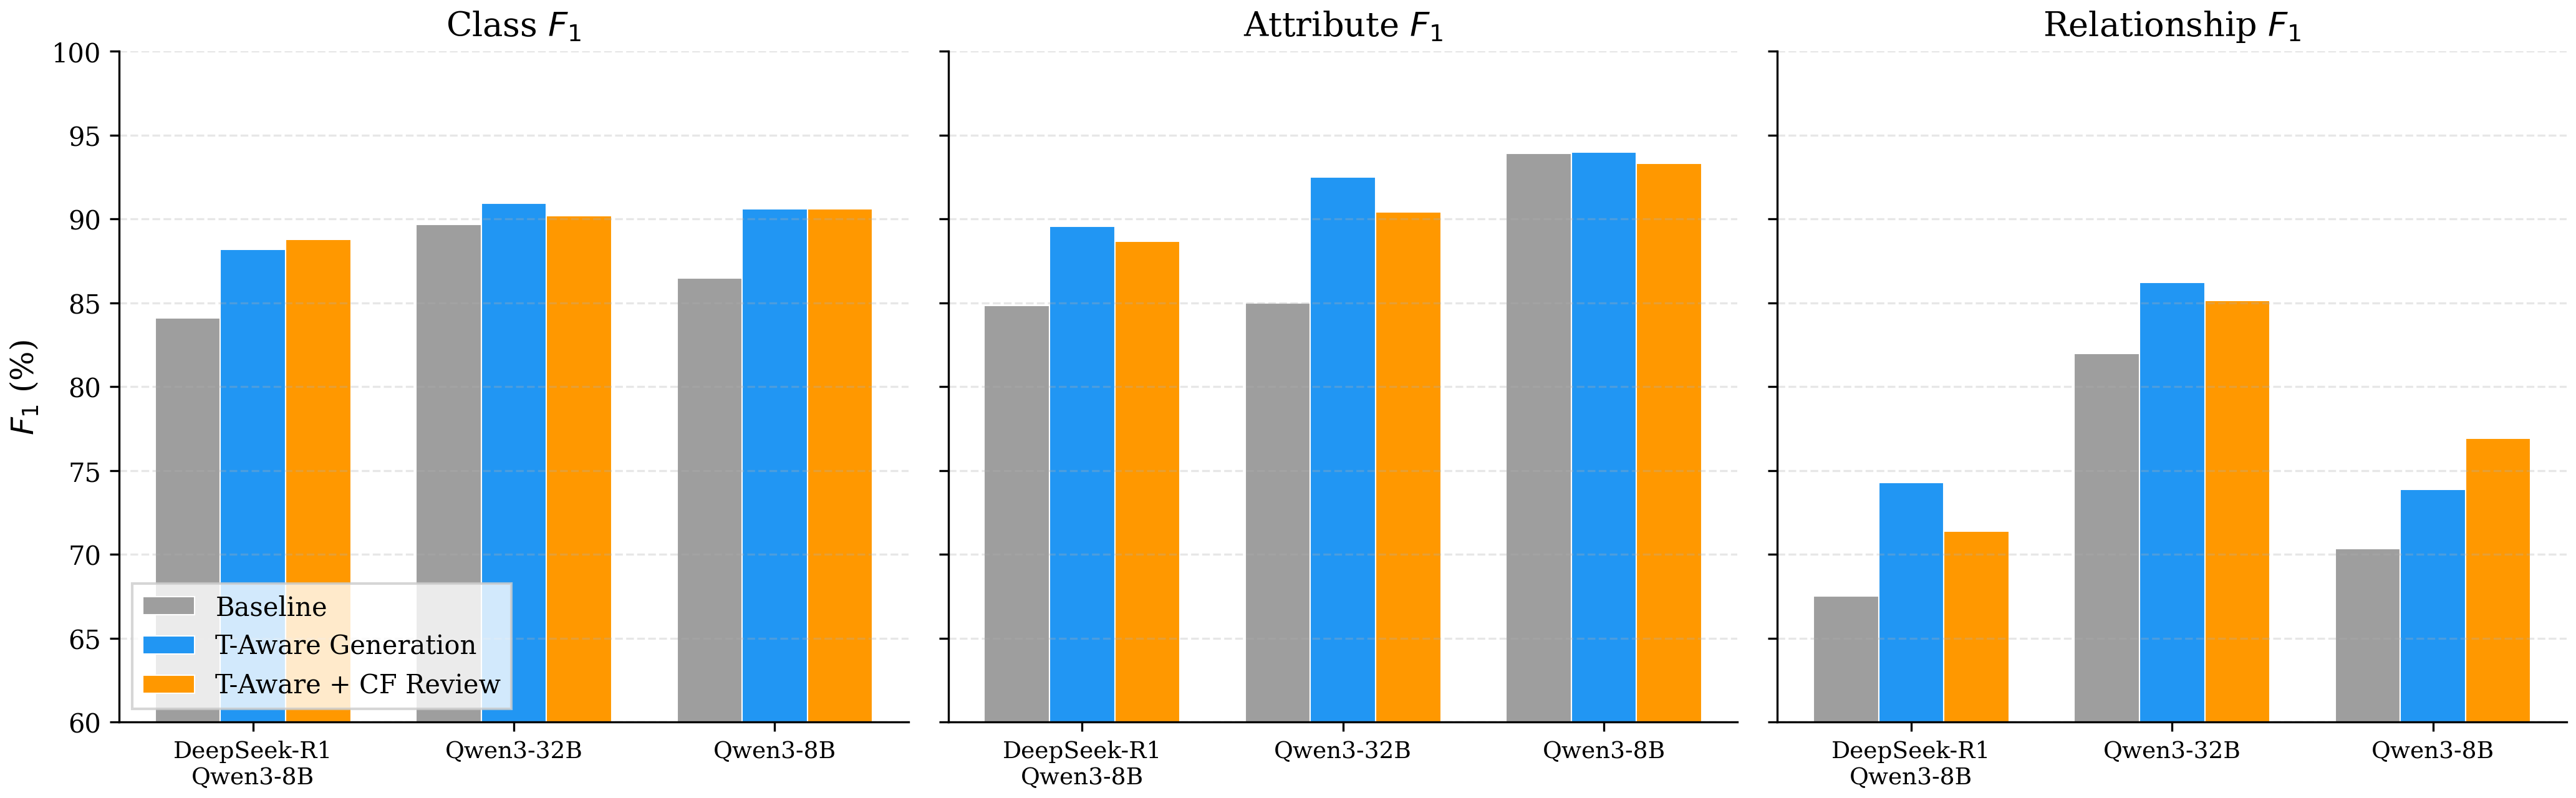

Saved: fig_dimension_f1_bar.pdf / .png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
dims = [('Class_F1', 'Class $F_1$'), ('Attr_F1', 'Attribute $F_1$'), ('Rel_F1', 'Relationship $F_1$')]
short_model_names = ['DeepSeek-R1\nQwen3-8B', 'Qwen3-32B', 'Qwen3-8B']
x = np.arange(len(model_names))
width = 0.25

for ax_idx, (dim_key, dim_label) in enumerate(dims):
    ax = axes[ax_idx]
    for i, cond in enumerate(CONDITIONS):
        means = [f1_results[m][cond][dim_key].mean() * 100 for m in model_names]
        ax.bar(x + i * width, means, width, label=cond if ax_idx == 0 else '',
               color=list(CONDITION_COLORS.values())[i], edgecolor='white', linewidth=0.5)
    ax.set_title(dim_label)
    ax.set_xticks(x + width)
    ax.set_xticklabels(short_model_names, fontsize=9)
    ax.set_ylim(60, 100)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.3, linestyle='--')

axes[0].set_ylabel('$F_1$ (%)')
axes[0].legend(frameon=True, fancybox=False, edgecolor='#cccccc', loc='lower left')

plt.tight_layout()
plt.savefig(f"{rootDir}/Figures/fig_dimension_f1_bar.pdf")
plt.savefig(f"{rootDir}/Figures/fig_dimension_f1_bar.png")
plt.show()
print("Saved: fig_dimension_f1_bar.pdf / .png")
